# CS224N 作业 1：探索词向量（25 分）
### <font color='blue'> 截止时间：1 月 17 日（周二）16:30 </font>

欢迎来到 CS224N！

开始前，请务必阅读与本 notebook 同目录下的 README.txt，其中包含重要的环境配置说明。本 notebook 中提供了大量代码，我们强烈建议你作为学习的一部分阅读并理解这些代码 :)

若你对 Python、NumPy 或 Matplotlib 不够熟悉，建议你参加周五的复习课。课程会录制，资料会发布在[课程网站](http://web.stanford.edu/class/cs224n/index.html#schedule)。CS231N 的 Python/NumPy [教程](https://cs231n.github.io/python-numpy-tutorial/)也是很好的资料。


**作业提示：** 请随时保存 notebook。提交说明见 notebook 末尾。

In [8]:
# 所有 import 语句均在此定义
# 注意：请勿向此列表添加其他项。
# ----------------

import sys

assert sys.version_info[0] == 3
assert sys.version_info[1] >= 5

from platform import python_version

assert int(python_version().split(".")[
               1]) >= 5, "请按照与本 notebook 同目录下 README.txt 中的说明升级 Python。你当前的 Python 版本为 " + python_version()

from gensim.models import KeyedVectors
from gensim.test.utils import datapath
import pprint
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = [10, 5]

import nltk

nltk.download('reuters', download_dir='./')  # 若要指定下载位置，可添加参数：download_dir='/指定/路径/'
from nltk.corpus import reuters

import numpy as np
import random
import scipy as sp
from sklearn.decomposition import TruncatedSVD
from sklearn.decomposition import PCA

START_TOKEN = '<START>'
END_TOKEN = '<END>'

np.random.seed(0)
random.seed(0)
# ----------------

[nltk_data] Downloading package reuters to ./...
[nltk_data]   Package reuters is already up-to-date!


## 词向量

词向量常作为下游 NLP 任务（如问答、文本生成、翻译等）的基础组件，因此有必要建立对其优势与局限的直观认识。此处你将探索两类词向量：一类来自*共现矩阵*，另一类来自 *GloVe*。

**术语说明：**「词向量」与「词嵌入」常互换使用。「嵌入」指将词义的若干方面编码到更低维的空间中。正如 [维基百科](https://en.wikipedia.org/wiki/Word_embedding) 所述：「*从概念上讲，它涉及从每个词一维的空间到维数低得多的连续向量空间的数学嵌入*」。

## 第一部分：基于计数的词向量（10 分）

多数词向量模型都源于如下思想：

*观其友，知其人（[Firth, J. R. 1957:11](https://en.wikipedia.org/wiki/John_Rupert_Firth)）*

许多词向量实现基于这样的假设：相似的词（即近义词）会出现在相似的上下文中，因而常与一组共现词（即语境）一起出现。通过考察这些语境，我们可以尝试为词学习嵌入。在这一直觉下，许多「传统」方法依赖词频统计来构造词向量。此处我们展开其中一种策略——*共现矩阵*（更多信息见[此处](https://web.stanford.edu/~jurafsky/slp3/6.pdf)或[此处](https://medium.com/data-science-group-iitr/word-embedding-2d05d270b285)）。

### 共现（Co-Occurrence）

共现矩阵统计在某种环境中事物共同出现的频率。给定文档中出现的词 $w_i$，我们考虑围绕 $w_i$ 的*上下文窗口*。设固定窗口大小为 $n$，则窗口包含该文档中 $w_i$ 前 $n$ 个词与后 $n$ 个词，即 $w_{i-n} \dots w_{i-1}$ 与 $w_{i+1} \dots w_{i+n}$。我们构造*共现矩阵* $M$，为对称的词–词矩阵，其中 $M_{ij}$ 表示在所有文档中 $w_j$ 出现在 $w_i$ 窗口内的次数。

**示例：窗口大小 n=1 的共现**：

文档 1："all that glitters is not gold"

文档 2："all is well that ends well"


|     *    | `<START>` | all | that | glitters | is   | not  | gold  | well | ends | `<END>` |
|----------|-------|-----|------|----------|------|------|-------|------|------|-----|
| `<START>`    | 0     | 2   | 0    | 0        | 0    | 0    | 0     | 0    | 0    | 0   |
| all      | 2     | 0   | 1    | 0        | 1    | 0    | 0     | 0    | 0    | 0   |
| that     | 0     | 1   | 0    | 1        | 0    | 0    | 0     | 1    | 1    | 0   |
| glitters | 0     | 0   | 1    | 0        | 1    | 0    | 0     | 0    | 0    | 0   |
| is       | 0     | 1   | 0    | 1        | 0    | 1    | 0     | 1    | 0    | 0   |
| not      | 0     | 0   | 0    | 0        | 1    | 0    | 1     | 0    | 0    | 0   |
| gold     | 0     | 0   | 0    | 0        | 0    | 1    | 0     | 0    | 0    | 1   |
| well     | 0     | 0   | 1    | 0        | 1    | 0    | 0     | 0    | 1    | 1   |
| ends     | 0     | 0   | 1    | 0        | 0    | 0    | 0     | 1    | 0    | 0   |
| `<END>`      | 0     | 0   | 0    | 0        | 0    | 0    | 1     | 1    | 0    | 0   |

**说明：** 在 NLP 中，我们常加入 `<START>` 与 `<END>` 标记表示句子、段落或文档的起止。此处可设想每个文档由 `<START>` 与 `<END>` 包裹，例如 "`<START>` All that glitters is not gold `<END>`"，并在共现统计中包含这些标记。

该矩阵的行（或列）可视为一类词向量（基于词–词共现），但向量维数通常很大（与语料中不同词的个数线性相关）。因此下一步是进行*降维*。具体而言，我们使用 *SVD（奇异值分解）*，它可视为广义的 *PCA（主成分分析）*，以选取前 $k$ 个主成分。下图示意用 SVD 降维：共现矩阵为 $A$，$n$ 行对应 $n$ 个词；完全分解后奇异值排在矩阵 $S$ 的对角线上，新的长度为 $k$ 的词向量在 $U_k$ 中。

![SVD 示意图](./imgs/svd.png "SVD")

降维后的共现表示往往能保留词之间的语义关系，例如 *doctor* 与 *hospital* 会比 *doctor* 与 *dog* 更接近。

**补充：** 若对特征值印象模糊，可参考这份[循序渐进、通俗易懂的 SVD 介绍](https://davetang.org/file/Singular_Value_Decomposition_Tutorial.pdf)。若想系统学习 PCA 或 SVD，可阅读 CS168 的[第 7](https://web.stanford.edu/class/cs168/l/l7.pdf)、[8](http://theory.stanford.edu/~tim/s15/l/l8.pdf)、[9](https://web.stanford.edu/class/cs168/l/l9.pdf) 讲。这些讲义从较高层次介绍了这些通用算法。就本课而言，你只需会用 numpy、scipy 或 sklearn 中已实现的算法提取 $k$ 维嵌入即可。实践中，对大语料做完整 SVD 往往受内存限制。若只需相对较小的 $k$ 对应的顶部 $k$ 个分量——即[截断 SVD（Truncated SVD）](https://en.wikipedia.org/wiki/Singular_value_decomposition#Truncated_SVD)——则有可扩展的迭代算法可用。

### 绘制共现词嵌入

此处使用路透社（商业与财经新闻）语料。若尚未运行本页顶部的 import 单元，请先运行（选中后按 Shift+Enter）。该语料含 10,788 篇新闻、约 130 万词，分 90 个类别，并划分为训练集与测试集。详见 https://www.nltk.org/book/ch02.html。下方提供 `read_corpus` 函数，仅抽取「gold」类（即黄金、矿业等相关报道）。该函数还会为每篇文档添加 `<START>`、`<END>` 标记，并将词转为小写。**无需**再做其他预处理。

In [9]:
def read_corpus(category="gold"):
    """ 读取指定路透社类别的文件。
        参数：
            category (str)：类别名称
        返回：
            由列表组成的列表，每个子列表为某篇处理后的文件的词序列
    """
    files = reuters.fileids(category)
    return [[START_TOKEN] + [w.lower() for w in list(reuters.words(f))] + [END_TOKEN] for f in files]


我们来看一看这些文档长什么样……

In [10]:
reuters_corpus = read_corpus()
pprint.pprint(reuters_corpus[:3], compact=True, width=100)

[['<START>', 'western', 'mining', 'to', 'open', 'new', 'gold', 'mine', 'in', 'australia', 'western',
  'mining', 'corp', 'holdings', 'ltd', '&', 'lt', ';', 'wmng', '.', 's', '>', '(', 'wmc', ')',
  'said', 'it', 'will', 'establish', 'a', 'new', 'joint', 'venture', 'gold', 'mine', 'in', 'the',
  'northern', 'territory', 'at', 'a', 'cost', 'of', 'about', '21', 'mln', 'dlrs', '.', 'the',
  'mine', ',', 'to', 'be', 'known', 'as', 'the', 'goodall', 'project', ',', 'will', 'be', 'owned',
  '60', 'pct', 'by', 'wmc', 'and', '40', 'pct', 'by', 'a', 'local', 'w', '.', 'r', '.', 'grace',
  'and', 'co', '&', 'lt', ';', 'gra', '>', 'unit', '.', 'it', 'is', 'located', '30', 'kms', 'east',
  'of', 'the', 'adelaide', 'river', 'at', 'mt', '.', 'bundey', ',', 'wmc', 'said', 'in', 'a',
  'statement', 'it', 'said', 'the', 'open', '-', 'pit', 'mine', ',', 'with', 'a', 'conventional',
  'leach', 'treatment', 'plant', ',', 'is', 'expected', 'to', 'produce', 'about', '50', ',', '000',
  'ounces', 'of', 'gold'

### 问题 1.1：实现 `distinct_words` [代码]（2 分）

编写函数，求语料中出现的不重复词（词型）。可用 `for` 循环，但用列表推导式通常更高效。将列表的列表「展平」为一维列表时，[此文](https://coderwall.com/p/rcmaea/flatten-a-list-of-lists-in-one-line-in-python)可能有帮助。若对列表推导式不熟悉，可参考[更多说明](https://python-3-patterns-idioms-test.readthedocs.io/en/latest/Comprehensions.html)。

返回的 `corpus_words` 应为排序后的列表，可使用 Python 的 `sorted`。

使用 [Python 集合（set）](https://www.w3schools.com/python/python_sets.asp) 去重往往很方便。

In [11]:
def distinct_words(corpus):
    """ 求语料中不重复词的列表。
        参数：
            corpus（由字符串列表组成的列表）：文档语料
        返回：
            corpus_words（字符串列表）：语料中所有不重复词经排序后的列表
            n_corpus_words（整数）：不重复词的个数
    """
    corpus_words = []
    n_corpus_words = -1

    ### 解答开始
    corpus_words = sorted({word for l in corpus for word in l})  # 遍历每个元素，然后放到set集合中
    n_corpus_words = len(corpus_words)
    ### 解答结束

    return corpus_words, n_corpus_words

In [12]:
# ---------------------
# 运行此简易检查
# 注意：这并非穷尽正确性的测试。
# ---------------------

# 定义玩具语料
test_corpus = ["{} All that glitters isn't gold {}".format(START_TOKEN, END_TOKEN).split(" "),
               "{} All's well that ends well {}".format(START_TOKEN, END_TOKEN).split(" ")]
test_corpus_words, num_corpus_words = distinct_words(test_corpus)

# 正确答案
ans_test_corpus_words = sorted(
    [START_TOKEN, "All", "ends", "that", "gold", "All's", "glitters", "isn't", "well", END_TOKEN])
ans_num_corpus_words = len(ans_test_corpus_words)

# 测试不重复词数量是否正确
assert (num_corpus_words == ans_num_corpus_words), "不重复词数量错误。正确值：{}。你的值：{}".format(ans_num_corpus_words,
                                                                                                 num_corpus_words)

# 测试词列表是否正确
assert (test_corpus_words == ans_test_corpus_words), "corpus_words 不正确。\n正确：{}\n你的：{}".format(
    str(ans_test_corpus_words), str(test_corpus_words))

# 打印通过信息
print("-" * 80)
print("已通过全部测试！")
print("-" * 80)

--------------------------------------------------------------------------------
已通过全部测试！
--------------------------------------------------------------------------------


### 问题 1.2：实现 `compute_co_occurrence_matrix` [代码]（3 分）

编写函数，为给定窗口大小 $n$（默认 4）构造共现矩阵：窗口中心词两侧各考虑 $n$ 个词。此处开始使用 `numpy (np)` 表示向量、矩阵与张量。若你不熟悉 NumPy，可参考 cs231n [Python NumPy 教程](http://cs231n.github.io/python-numpy-tutorial/)后半部分的 NumPy 入门。


In [13]:
def compute_co_occurrence_matrix(corpus, window_size=4):
    """ 对给定语料与 window_size（默认 4）计算共现矩阵。
    
        说明：文档中每个词都应作为某次窗口的中心；靠近边界的词其共现词数量会较少。
              
              例如文档 "<START> All that glitters is not gold <END>" 在窗口大小为 4 时，
              "All" 会与 "<START>"、"that"、"glitters"、"is"、"not" 共现。
    
        参数：
            corpus（由字符串列表组成的列表）：文档语料
            window_size（int）：上下文窗口大小
        返回：
            M（形状为（语料中不重复词数，语料中不重复词数）的对称 numpy 矩阵）：
                词频共现矩阵；行/列中词的顺序须与 distinct_words 返回的顺序一致。
            word2ind（dict）：词到矩阵 M 中行/列下标的映射。
    """
    words, n_words = distinct_words(corpus)
    M = None
    word2ind = {}

    ### 解答开始
    word2ind = {w: i for i, w in enumerate(words)}  # 词到矩阵 M 中行/列下标的映射
    M = np.zeros((len(words), len(words)),dtype=np.int64)
    for doc in corpus:
        for j in range(len(doc)):
            center_word = doc[j]   # 当前中心词
            ci = word2ind[center_word]  # 中心词在共线矩阵中的位置
            for k in range(j-window_size,j+window_size+1):
                if(k<0 or k>=len(doc) or k == j):
                    continue
                outer_word = doc[k]  # 获取周围的单词
                M[ci,word2ind[outer_word]] += 1.0
    ### 解答结束

    return M, word2ind

In [14]:
# ---------------------
# 运行此简易检查
# 注意：这并非穷尽正确性的测试。
# ---------------------

# 定义玩具语料并获取学生的共现矩阵
test_corpus = ["{} All that glitters isn't gold {}".format(START_TOKEN, END_TOKEN).split(" "),
               "{} All's well that ends well {}".format(START_TOKEN, END_TOKEN).split(" ")]
M_test, word2ind_test = compute_co_occurrence_matrix(test_corpus, window_size=1)

# 正确的 M 与 word2ind
M_test_ans = np.array(
    [[0., 0., 0., 0., 0., 0., 1., 0., 0., 1., ],
     [0., 0., 1., 1., 0., 0., 0., 0., 0., 0., ],
     [0., 1., 0., 0., 0., 0., 0., 0., 1., 0., ],
     [0., 1., 0., 0., 0., 0., 0., 0., 0., 1., ],
     [0., 0., 0., 0., 0., 0., 0., 0., 1., 1., ],
     [0., 0., 0., 0., 0., 0., 0., 1., 1., 0., ],
     [1., 0., 0., 0., 0., 0., 0., 1., 0., 0., ],
     [0., 0., 0., 0., 0., 1., 1., 0., 0., 0., ],
     [0., 0., 1., 0., 1., 1., 0., 0., 0., 1., ],
     [1., 0., 0., 1., 1., 0., 0., 0., 1., 0., ]]
)
ans_test_corpus_words = sorted(
    [START_TOKEN, "All", "ends", "that", "gold", "All's", "glitters", "isn't", "well", END_TOKEN])
word2ind_ans = dict(zip(ans_test_corpus_words, range(len(ans_test_corpus_words))))

# 测试 word2ind 是否正确
assert (word2ind_ans == word2ind_test), "你的 word2ind 不正确：\n正确：{}\n你的：{}".format(word2ind_ans, word2ind_test)

# 测试 M 的形状
assert (M_test.shape == M_test_ans.shape), "矩阵 M 形状错误。\n正确：{}\n你的：{}".format(M_test.shape, M_test_ans.shape)

# 测试 M 的元素值
for w1 in word2ind_ans.keys():
    idx1 = word2ind_ans[w1]
    for w2 in word2ind_ans.keys():
        idx2 = word2ind_ans[w2]
        student = M_test[idx1, idx2]
        correct = M_test_ans[idx1, idx2]
        if student != correct:
            print("正确的 M：")
            print(M_test_ans)
            print("你的 M：")
            print(M_test)
            raise AssertionError(
                "矩阵 M 在索引 ({}, {})=({}, {}) 处计数错误。你的值为 {}，应为 {}。".format(idx1, idx2, w1, w2, student,
                                                                                         correct))

# 打印通过信息
print("-" * 80)
print("已通过全部测试！")
print("-" * 80)

--------------------------------------------------------------------------------
已通过全部测试！
--------------------------------------------------------------------------------


### 问题 1.3：实现 `reduce_to_k_dim` [代码]（1 分）

编写函数，对矩阵做降维以得到 $k$ 维词嵌入。使用 SVD 取前 $k$ 个分量，得到 $k$ 维嵌入矩阵。

**说明：** numpy、scipy、scikit-learn（`sklearn`）均提供*某种* SVD 实现，但只有 scipy 与 sklearn 提供截断 SVD（Truncated SVD），且大规模截断 SVD 的高效随机算法仅在 sklearn 中。因此请使用 [sklearn.decomposition.TruncatedSVD](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.TruncatedSVD.html)。

In [15]:
def reduce_to_k_dim(M, k=2):
    """ 将形状为 (num_corpus_words, num_corpus_words) 的共现计数矩阵
        降为 (num_corpus_words, k)，使用 Scikit-Learn 的 SVD：
            - http://scikit-learn.org/stable/modules/generated/sklearn.decomposition.TruncatedSVD.html
    
        参数：
            M（形状为（语料不重复词数，语料不重复词数）的 numpy 矩阵）：词频共现矩阵
            k（int）：降维后每个词的嵌入维度
        返回：
            M_reduced（形状为（语料词数，k）的 numpy 矩阵）：$k$ 维词嵌入矩阵。
                    按课堂上的 SVD 记号，实际返回的是 U * S
    """
    n_iters = 10  # 调用 `TruncatedSVD` 时使用此参数
    M_reduced = None
    print("正在对 %i 个词运行截断 SVD..." % (M.shape[0]))

    ### 解答开始
    svd = TruncatedSVD(n_components=k, n_iter=n_iters, random_state=0)
    M_reduced = svd.fit_transform(M)
    ### 解答结束

    print("完成。")
    return M_reduced

In [16]:
# ---------------------
# 运行此简易检查
# 注意：这并非穷尽正确性的测试
# 实际上我们只检查你的 M_reduced 维度是否正确。
# ---------------------

# 定义玩具语料并运行学生代码
test_corpus = ["{} All that glitters isn't gold {}".format(START_TOKEN, END_TOKEN).split(" "),
               "{} All's well that ends well {}".format(START_TOKEN, END_TOKEN).split(" ")]
M_test, word2ind_test = compute_co_occurrence_matrix(test_corpus, window_size=1)
M_test_reduced = reduce_to_k_dim(M_test, k=2)

# 测试维度是否正确
assert (M_test_reduced.shape[0] == 10), "M_reduced 有 {} 行；应为 {} 行".format(M_test_reduced.shape[0], 10)
assert (M_test_reduced.shape[1] == 2), "M_reduced 有 {} 列；应为 {} 列".format(M_test_reduced.shape[1], 2)

# 打印通过信息
print("-" * 80)
print("已通过全部测试！")
print("-" * 80)

正在对 10 个词运行截断 SVD...
完成。
--------------------------------------------------------------------------------
已通过全部测试！
--------------------------------------------------------------------------------


### 问题 1.4：实现 `plot_embeddings` [代码]（1 分）

编写函数，在二维平面上绘制一组二维向量。作图使用 Matplotlib（`plt`）。

本例可参考并改写[这段代码](http://web.archive.org/web/20190924160434/https://www.pythonmembers.club/2018/05/08/matplotlib-scatter-plot-annotate-set-text-at-label-each-point/)。以后作图时，可在 [Matplotlib 图库](https://matplotlib.org/gallery/index.html)中找到风格相近的示例再改写。

In [23]:
def plot_embeddings(M_reduced, word2ind, words):
    """ 在散点图中绘制列表 words 中指定词的嵌入。
        注意：不要绘制 M_reduced / word2ind 中的全部词。
        在每个点旁标注标签。

        参数：
            M_reduced（形状为（语料不重复词数，2）的 numpy 矩阵）：二维词嵌入矩阵
            word2ind（dict）：词到矩阵行索引的映射
            words（字符串列表）：要可视化的词
    """

    ### 解答开始
    xs = [M_reduced[word2ind[w], 0] for w in words]
    ys = [M_reduced[word2ind[w], 1] for w in words]
    plt.scatter(xs, ys)
    for w in words:
        i = word2ind[w]
        plt.annotate(w, (M_reduced[i, 0], M_reduced[i, 1]))
    plt.show()
    ### 解答结束

--------------------------------------------------------------------------------
输出图像：


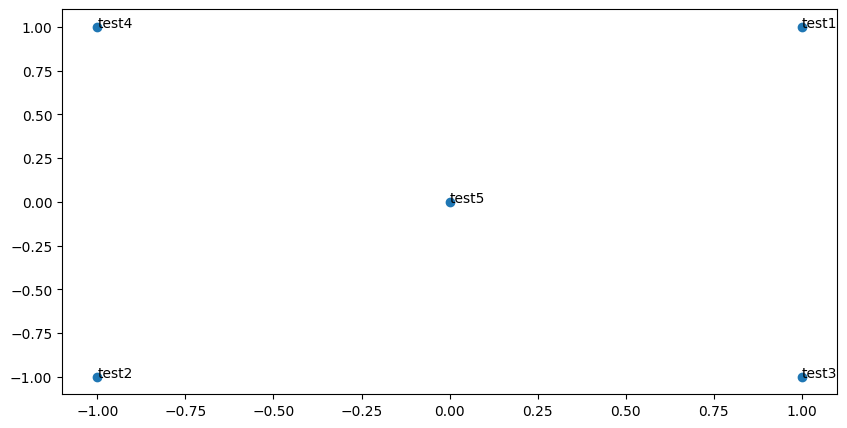

--------------------------------------------------------------------------------


In [24]:
# ---------------------
# 运行此简易检查
# 注意：这并非穷尽正确性的测试。
# 生成的图应与下方「测试参考图」类似。
# ---------------------

print("-" * 80)
print("输出图像：")

M_reduced_plot_test = np.array([[1, 1], [-1, -1], [1, -1], [-1, 1], [0, 0]])
word2ind_plot_test = {'test1': 0, 'test2': 1, 'test3': 2, 'test4': 3, 'test5': 4}
words = ['test1', 'test2', 'test3', 'test4', 'test5']
plot_embeddings(M_reduced_plot_test, word2ind_plot_test, words)

print("-" * 80)

### 问题 1.5：共现图分析 [书面]（3 分）

下面将你写好的各部分拼起来：在路透社「gold」语料上，用固定窗口 4（默认窗口大小）计算共现矩阵，再用 TruncatedSVD 得到每个词的二维嵌入。TruncatedSVD 返回的是 U\*S，因此需要对返回向量做归一化，使各向量落在单位圆附近（此时「接近」表示方向上的接近）。**说明**：下面归一化那行代码使用了 NumPy 的*广播*（broadcasting）。若不了解广播，可读
[《数组计算：广播》Jake VanderPlas](https://jakevdp.github.io/PythonDataScienceHandbook/02.05-computation-on-arrays-broadcasting.html)。

运行下方单元格生成图像，可能需要数秒。

正在对 2830 个词运行截断 SVD...
完成。
[[ 0.98182625  0.18978203]
 [ 0.96337056  0.26817376]
 [ 0.97087267 -0.23959605]
 [ 0.98806977 -0.1540069 ]
 [ 0.98701186 -0.16064737]]


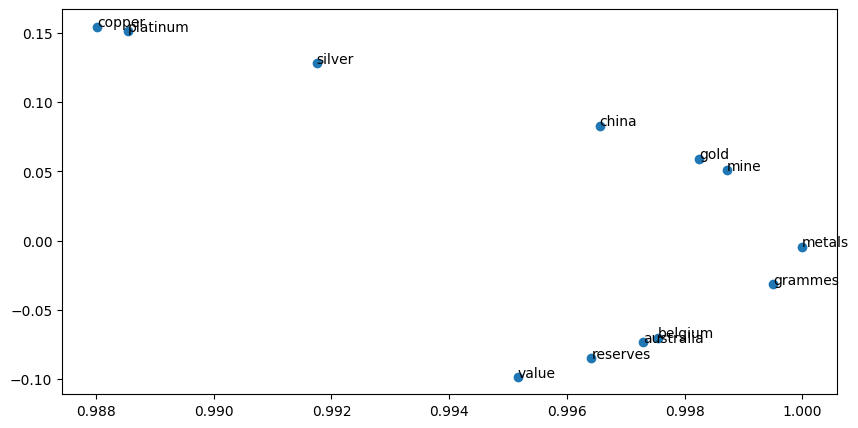

In [27]:
# -----------------------------
# 运行此单元格生成你的图
# ------------------------------
reuters_corpus = read_corpus()
M_co_occurrence, word2ind_co_occurrence = compute_co_occurrence_matrix(reuters_corpus)
M_reduced_co_occurrence = reduce_to_k_dim(M_co_occurrence, k=2) # 降低到二维

# 将各行重标度（归一化）为单位长度
M_lengths = np.linalg.norm(M_reduced_co_occurrence, axis=1) #得到一个一维向量，代表L2范数
M_normalized = M_reduced_co_occurrence / M_lengths[:, np.newaxis]  # 广播
print(M_normalized[:5])

words = ['value', 'gold', 'platinum', 'reserves', 'silver', 'metals', 'copper', 'belgium', 'australia', 'china',
         'grammes', "mine"]

plot_embeddings(M_normalized, word2ind_co_occurrence, words)

**请确认你的图与作业压缩包中的「question_1.5.png」一致。若不一致，可用该参考图回答下面两问。**

a. 在二维嵌入空间中找出至少两组聚在一起的词，并对每组给出解释。

### 解答开始
+ platinum（铂金）和copper（铜） ：copper mine 铜矿和platinum mine 铂金矿
+ glod和mine ：gold mine 金矿，捕捉到这对上下文关联词，他俩距离很近
+ belgium和australia:Belgium(比利时) 盛产钻石 Australia 盛产黄金、铁矿、煤炭
### 解答结束


b. 哪些词你认为本应聚在一起却没有？请至少举两例说明。

### 解答开始
+ china和australia :两个国家，说明china周围没有出现glod等矿产信息，所以他被隔离了
+ copper和mine：copper mine铜矿
+ glod和copper：glod copper 和 copper mine 他俩都是金属，因为只去了两个维度（方差最大的），所以这个维度可能被忽略了
### 解答结束

## 第二部分：基于预测的词向量（15 分）

如课堂所述，近年来基于预测的词向量（如 word2vec、以及同时利用计数信息的 GloVe）往往表现更好。此处将探索 GloVe 产生的嵌入。word2vec 与 GloVe 的细节见课程笔记与讲义；若有余力可阅读 [GloVe 原文](https://nlp.stanford.edu/pubs/glove.pdf)。

然后运行下列单元格将 GloVe 向量载入内存。**说明**：若首次运行（需下载嵌入模型），可能需数分钟；若曾运行过，再次运行会跳过下载，约 1–2 分钟。

In [28]:
def load_embedding_model():
    """ 加载 GloVe 词向量
        返回：
            wv_from_bin：共 400000 个词向量，每个维度为 200
    """
    import gensim.downloader as api
    wv_from_bin = api.load("glove-wiki-gigaword-200")
    print("已加载词表大小：%i" % len(list(wv_from_bin.index_to_key)))
    return wv_from_bin

In [29]:
# -----------------------------------
# 运行此单元格加载词向量
# 说明：可能需要数分钟
# -----------------------------------
wv_from_bin = load_embedding_model()

已加载词表大小：400000


#### 说明：若出现「reset by peer」错误，请重新运行该单元格以下载。若出现「attribute」类错误，可能需要将 gensim 与 numpy 升级到最新版本。可取消下方单元格注释并运行以在环境中升级：

In [ ]:
#!pip install gensim --upgrade
#!pip install numpy --upgrade

### 词嵌入的降维
将 GloVe 嵌入与共现矩阵得到的嵌入直接对比。为避免内存不足，我们仅使用 10000 个 GloVe 向量样本。
依次运行下列单元格以：

1. 将 10000 个 GloVe 向量放入矩阵 M
2. 运行 `reduce_to_k_dim`（你实现的截断 SVD）将向量从 200 维降维到 2 维

In [41]:
def get_matrix_of_vectors(wv_from_bin, required_words):
    """ 将 GloVe 向量放入矩阵 M。
        参数：
            wv_from_bin：KeyedVectors 对象，自文件加载的 400000 个 GloVe 向量
        返回：
            M：形状为 (词数, 200) 的 numpy 矩阵，存放向量
            word2ind：词到 M 中行号的映射
    """
    import random
    words = list(wv_from_bin.index_to_key)
    print("正在打乱词序...")
    random.seed(225)
    random.shuffle(words)
    words = words[:10000]
    print("正将 %i 个词写入 word2ind 与矩阵 M..." % len(words))
    word2ind = {}
    M = []
    curInd = 0
    # 随机抽样的10000个词放到M（共现矩阵）中
    for w in words:
        try:
            M.append(wv_from_bin.get_vector(w))
            word2ind[w] = curInd
            curInd += 1
        except KeyError:
            continue
    # 将待分析的词也加入M中
    for w in required_words:
        if w in words:
            continue
        try:
            M.append(wv_from_bin.get_vector(w))
            word2ind[w] = curInd
            curInd += 1
        except KeyError:
            continue
    M = np.stack(M)
    print("完成。")
    return M, word2ind

In [42]:
# -----------------------------------------------------------------
# 运行此单元格将 200 维词嵌入降为 k 维
# 说明：通常很快
# -----------------------------------------------------------------
M, word2ind = get_matrix_of_vectors(wv_from_bin, words)
M_reduced = reduce_to_k_dim(M, k=2)

# 将各行重标度（归一化）为单位长度
M_lengths = np.linalg.norm(M_reduced, axis=1)
M_reduced_normalized = M_reduced / M_lengths[:, np.newaxis]  # 广播

正在打乱词序...
正将 10000 个词写入 word2ind 与矩阵 M...
完成。
正在对 10012 个词运行截断 SVD...
完成。


**说明：若本机内存不足，请关闭其他应用以释放内存，或重启机器后再立即打开 Jupyter 运行本 notebook，确认能否正常加载词向量。若仍无法在本机加载嵌入，请参加答疑或联系课程助教。**

### 问题 2.1：GloVe 图分析 [书面]（3 分）

运行下方单元格，绘制以下词的二维 GloVe 嵌入：`['value', 'gold', 'platinum', 'reserves', 'silver', 'metals', 'copper', 'belgium', 'australia', 'china', 'grammes', "mine"]`。

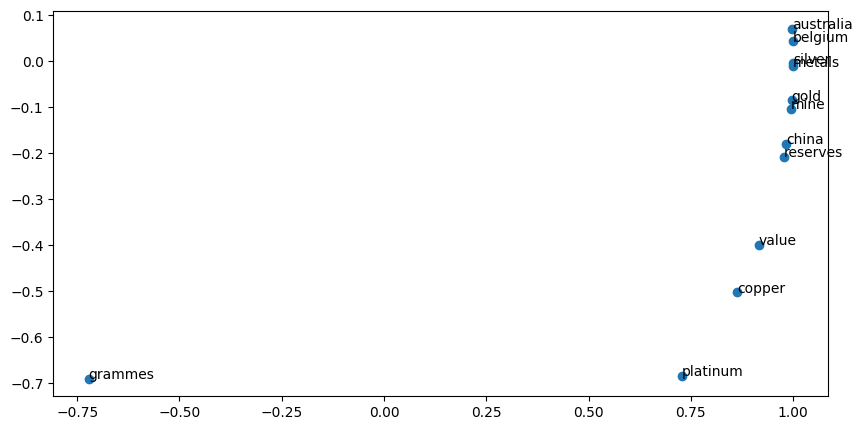

In [43]:
words = ['value', 'gold', 'platinum', 'reserves', 'silver', 'metals', 'copper', 'belgium', 'australia', 'china',
         'grammes', "mine"]

plot_embeddings(M_reduced_normalized, word2ind, words)

a. 与先前由共现矩阵生成的图相比，有何不同？又有何相似之处？（各答一点即可）

### 解答开始
+ 不同：GloVe 的二维图通常更“语义化/全局一致”，会更清楚地把金属/商品（gold/silver/platinum/copper/metals）聚成一团、把国家（china/australia/belgium）聚成一团；而共现矩阵（只用 Reuters 的 “gold” 主题语料）更容易受语料主题、**稀疏共现**和噪声影响，点位更散、偶尔出现不直观的邻近。
+ 相似：两张图里通常仍能看到一些直观关系保持一致，比如 gold/silver/platinum 相互更近、mine 往往更靠近矿产/金属相关词（如 gold 或 copper），说明两者都捕捉到了“同现/语义相关性”的一部分。
### 解答结束

b. 造成上述差异的可能原因是什么？

### 解答开始
+ 训练数据与目标不同：GloVe 是在更大规模通用语料上训练的预测式/加权全局共现模型，学到更稳定的语义几何结构；你的共现矩阵只来自 Reuters 的 “gold” 相关文档，语料更小且主题更窄，导致表示更“领域化”且更噪声。
+ 统计处理不同：你对共现矩阵是“原始计数 → SVD → 2 维 → 归一化”，原始计数会被高频词/窗口设置影响，SVD 到 2 维也会丢掉大量信息；GloVe 的训练过程相当于对共现信息做了更合理的加权与分解（更接近对 PMI/对数共现的结构学习），所以可视化更清晰。
### 解答结束

### 余弦相似度
有了词向量后，需要一种度量来刻画词与词之间的相似程度；余弦相似度即其一，我们将用它寻找彼此「近」或「远」的词。

可将 $n$ 维向量视为 $n$ 维空间中的点。在此视角下，[L1](http://mathworld.wolfram.com/L1-Norm.html) 与 [L2](http://mathworld.wolfram.com/L2-Norm.html) 距离刻画两点间「需走过的距离」。另一种做法是考察两向量夹角。由三角关系可知：

<img src="./imgs/inner_product.png" width=20% style="float: center;"></img>

不必算出真实夹角，可直接用 $s = \cos(\Theta)$ 表示相似程度。形式上，两向量 $p$ 与 $q$ 的[余弦相似度](https://en.wikipedia.org/wiki/Cosine_similarity) $s$ 定义为：

$$s = \frac{p \cdot q}{||p|| ||q||}, \textrm{其中 } s \in [-1, 1] $$ 

### 问题 2.2：多义词（1.5 分）[代码 + 书面]
一词多义与同形异义词均指具有多个义项的词（参见[维基页面](https://en.wikipedia.org/wiki/Polysemy)了解二者区别）。请找出一个*至少含两种不同义项*的词，使其在余弦相似度下最相近的前 10 个词中，*同时*出现与两种义项相关的词。例如 "leaves" 的前 10 近邻中既有与「离开」相关也有与「植物叶片」相关；"scoop" 则兼有「蛋筒」与「内幕」等。你可能需要多试几个多义词或同形词才能找到合适的例子。

请写出你找到的词，并说明前 10 近邻中如何体现多种义项。你认为为何许多你试过的多义词不「奏效」（即前 10 个最相似词只体现**一种**义项）？

**说明**：请使用 `wv_from_bin.most_similar(word)` 获取最相近的 10 个词；该函数按与目标词的余弦相似度对词表中其余词排序。更多用法见 __[Gensim 文档](https://radimrehurek.com/gensim/models/keyedvectors.html#gensim.models.keyedvectors.FastTextKeyedVectors.most_similar)__。

In [44]:
### 解答开始
#多义词在静态词向量里的典型局限
word = "apple"
word_list = wv_from_bin.most_similar(word)  #跟苹果最相近的10个单词
print(word_list)  # 没有和水果相关的,因为apple与公司不是多义词，但是apple不应该没有水果的意思

word = "leaves"
word_list = wv_from_bin.most_similar(word)  #
print(word_list)
### 解答结束

[('iphone', 0.6271388530731201), ('microsoft', 0.6061939001083374), ('intel', 0.599233090877533), ('macintosh', 0.5989753603935242), ('ipod', 0.5908078551292419), ('ibm', 0.5888804793357849), ('ipad', 0.5876859426498413), ('software', 0.5711662173271179), ('google', 0.5554560422897339), ('itunes', 0.5478185415267944)]
[('ends', 0.6128067970275879), ('leaf', 0.6027014255523682), ('stems', 0.5998532176017761), ('takes', 0.5902854204177856), ('leaving', 0.5761634707450867), ('grows', 0.5663397312164307), ('flowers', 0.5600922107696533), ('turns', 0.5536050796508789), ('leave', 0.5496848821640015), ('goes', 0.5434925556182861)]


### 解答开始

### 解答结束

### 问题 2.3：同义词与反义词（2 分）[代码 + 书面]

讨论余弦相似度时，常改用余弦距离，定义为 1 减去余弦相似度。

请找出三个词 $(w_1,w_2,w_3)$，使得 $w_1$ 与 $w_2$ 为同义词、$w_1$ 与 $w_3$ 为反义词，但余弦距离满足 $(w_1,w_3) <$ $(w_1,w_2)$。

例如 $w_1$="happy" 到 $w_3$="sad" 的距离反而小于到 $w_2$="cheerful"。请另举一个满足上述条件的不同例子，并解释这一反直觉现象的可能原因。

请使用 `wv_from_bin.distance(w1, w2)` 计算两词余弦距离。详见 __[Gensim 文档](https://radimrehurek.com/gensim/models/keyedvectors.html#gensim.models.keyedvectors.FastTextKeyedVectors.distance)__。

In [45]:
### 解答开始

w1 = "happy"
w2 = "cheerful"
w3 = "sad"
w1_w2_dist = wv_from_bin.distance(w1, w2)
w1_w3_dist = wv_from_bin.distance(w1, w3)

print("同义词 {}, {} 的余弦距离：{}".format(w1, w2, w1_w2_dist))
print("反义词 {}, {} 的余弦距离：{}".format(w1, w3, w1_w3_dist))

### 解答结束

同义词 happy, cheerful 的余弦距离：0.5172467231750488
反义词 happy, sad 的余弦距离：0.4040136933326721


### 解答开始
静态词向量主要反映上下文分布相似性，而不是逻辑上的同义/反义；反义词经常出现在相似上下文里，所以可能比同义词更近
### 解答结束

### 问题 2.4：词向量与类比 [书面]（1.5 分）
词向量*有时*能用于解答类比题。

例如类比「man : grandfather :: woman : x」（即 man 之于 grandfather 犹如 woman 之于 x），x 是什么？

下方单元格演示如何用词向量与 `most_similar`（见 __[Gensim 文档](https://radimrehurek.com/gensim/models/keyedvectors.html#gensim.models.keyedvectors.KeyedVectors.most_similar)__）求 x：该函数寻找与 `positive` 列表中词最相近、与 `negative` 列表中词最不相近的词（并常排除输入词本身，因其往往最相似；见[此文](https://www.aclweb.org/anthology/N18-2039.pdf)）。类比答案对应余弦相似度最高（返回数值最大）的词。

In [ ]:
# 运行此单元格解答类比：man : grandfather :: woman : x
# postitice是加法 negatice是减法
pprint.pprint(wv_from_bin.most_similar(positive=['woman', 'grandfather'], negative=['man']))

[('grandmother', 0.7608445286750793),
 ('granddaughter', 0.7200808525085449),
 ('daughter', 0.7168302536010742),
 ('mother', 0.7151536345481873),
 ('niece', 0.7005682587623596),
 ('father', 0.6659888029098511),
 ('aunt', 0.6623409390449524),
 ('grandson', 0.6618767976760864),
 ('grandparents', 0.644661009311676),
 ('wife', 0.6445354223251343)]


设 $m$、$g$、$w$、$x$ 分别为 `man`、`grandfather`、`woman` 与答案的词向量。在答案中**仅**使用 $m$、$g$、$w$ 及向量运算 $+$、$-$，我们应使 $x$ 与哪个表达式的余弦相似度最大？

提示：词向量即表示词的多维向量。可在二维平面上任意画出各向量位置以帮助思考：`man` 与 `woman` 相对 `grandfather` 与答案应大致在何方位？

### 解答开始
x≈w+(g−m)=w+g−m
### 解答结束

### 问题 2.5：寻找类比 [代码 + 书面]（1.5 分）
a. 上一例中，完成类比的词显然是 "grandmother"。请直观解释为何 `most_similar` 还会给出 "granddaughter"、"daughter"、"mother" 等词？

### 解答开始
因为 most_similar 返回的是离目标向量最近的一批词，而目标向量 
v
(
woman
)
+
v
(
grandfather
)
−
v
(
man
)
v(woman)+v(grandfather)−v(man) 表示的关系大致是“把 man→grandfather 的‘代际/亲属’变化，加到 woman 上”。
在词向量空间里，这个目标点不会精确落在 grandmother 上，而是落在一个“女性亲属/家庭关系”的区域附近，所以：

grandmother 最接近（最符合“女性版的 grandfather”）。
mother / daughter / granddaughter 等词也共享大量“女性 + 家庭亲属 + 代际”语义特征，与该目标向量也很接近，因此会被列在前几个近邻里。
### 解答结束

b. 找出一个在这些向量下成立类比（即目标词排在首位）的例子。请用 x:y :: a:b 写出完整类比。若你认类比较绕，可用一两句话说明为何成立。

**说明**：你可能需要多试几组类比才能找到成立的例子！

In [51]:
### 解答开始

x, y, a, b = ("man","king","woman","queen")
print(wv_from_bin.most_similar(positive=[a, y], negative=[x]))
assert wv_from_bin.most_similar(positive=[a, y], negative=[x])[0][0] == b

### 解答结束

[('queen', 0.6978678107261658), ('princess', 0.6081745028495789), ('monarch', 0.5889754891395569), ('throne', 0.5775108933448792), ('prince', 0.5750998258590698), ('elizabeth', 0.5463595986366272), ('daughter', 0.5399126410484314), ('kingdom', 0.5318052768707275), ('mother', 0.5168544054031372), ('crown', 0.5164473056793213)]


### 解答开始
woman + king - man = queen
### 解答结束

### 问题 2.6：不成立的类比 [代码 + 书面]（1.5 分）
a. 下面我们期望看到类比「hand : glove :: foot : **sock**」，但实际结果却不同。请分析这一类比为何可能得到意外结果？

In [52]:
pprint.pprint(wv_from_bin.most_similar(positive=['foot', 'glove'], negative=['hand']))

[('45,000-square', 0.4922032654285431),
 ('15,000-square', 0.4649604558944702),
 ('10,000-square', 0.4544755816459656),
 ('6,000-square', 0.44975775480270386),
 ('3,500-square', 0.444133460521698),
 ('700-square', 0.44257497787475586),
 ('50,000-square', 0.4356396794319153),
 ('3,000-square', 0.43486514687538147),
 ('30,000-square', 0.4330596923828125),
 ('footed', 0.43236875534057617)]


### 解答开始
foot + glove - hand = 应该是袜子之类的，这个类比失败通常因为“hand→glove”的向量差并不代表一个干净、可迁移的关系，所以映射到 foot 时会被语料统计偏置带偏。也就是sock和glove不够线性。
### 解答结束

b. 再找一个在这些向量下*不*成立的类比。请写出你期望的类比 x:y :: a:b，并写出词向量实际给出的**错误** b（上一小问中，该错误答案为 **'45,000-square'**）。

In [55]:
### 解答开始

x, y, a, b = ["shoe","lace","cup","lid"]
pprint.pprint(wv_from_bin.most_similar(positive=[a, y], negative=[x]))
### 解答结束

[('cups', 0.5253069400787354),
 ('champions', 0.4824543595314026),
 ('finals', 0.45731163024902344),
 ('quarterfinals', 0.45226356387138367),
 ('semifinal', 0.45105600357055664),
 ('semi-final', 0.44856423139572144),
 ('semifinals', 0.4473054111003876),
 ('semi-finals', 0.43491917848587036),
 ('championship', 0.4269707500934601),
 ('qualifiers', 0.41629838943481445)]


### 解答开始
cup + (lace - shoe) = lid ,(lace - shoe)的差值并不是一个可迁移的向量，也就是cup 与 lid之间不是简单的线性关系
### 解答结束

### 问题 2.7：词向量偏见的引导分析 [书面]（1 分）

有必要意识到词嵌入中隐含的偏见（性别、种族、性取向等）。使用这些模型的应用可能放大刻板印象，因而具有风险。

运行下方单元格，观察（a）与 "woman"、"profession" 最相近且与 "man" 最不相近的词有哪些；（b）与 "man"、"profession" 最相近且与 "woman" 最不相近的词有哪些。指出两组词表的差异，并说明其如何反映性别偏见。

In [56]:
# 运行此单元格
# 此处 `positive` 为希望与之相近的词列表，`negative` 为希望与之尽可能不相近的词列表。

pprint.pprint(wv_from_bin.most_similar(positive=['man', 'profession'], negative=['woman']))
print()
pprint.pprint(wv_from_bin.most_similar(positive=['woman', 'profession'], negative=['man']))

[('reputation', 0.5250176787376404),
 ('professions', 0.5178037881851196),
 ('skill', 0.49046966433525085),
 ('skills', 0.49005505442619324),
 ('ethic', 0.4897659420967102),
 ('business', 0.487585186958313),
 ('respected', 0.485920250415802),
 ('practice', 0.482104629278183),
 ('regarded', 0.4778572916984558),
 ('life', 0.4760662019252777)]

[('professions', 0.5957457423210144),
 ('practitioner', 0.49884122610092163),
 ('teaching', 0.48292139172554016),
 ('nursing', 0.48211804032325745),
 ('vocation', 0.4788965880870819),
 ('teacher', 0.47160351276397705),
 ('practicing', 0.46937814354896545),
 ('educator', 0.46524327993392944),
 ('physicians', 0.4628995358943939),
 ('professionals', 0.4601394236087799)]


### 解答开始
man + (professon - woman) = profession，但是却给出了reputation，第二个答案才是profession;相反，woman +(professon-man)= prefession。这就是一种对性别的偏见
### 解答结束

### 问题 2.8：词向量偏见的独立分析 [代码 + 书面]（1 分）

使用 `most_similar` 再找另一组能体现向量偏见的类比对，并简要说明你发现的偏见现象。

In [62]:
### 解答开始

A = "woman"
B = "man"
word = "smoker"
pprint.pprint(wv_from_bin.most_similar(positive=[A, word], negative=[B]))
print()
pprint.pprint(wv_from_bin.most_similar(positive=[B, word], negative=[A]))

### 解答结束

[('smokers', 0.5818895101547241),
 ('nonsmoker', 0.49043798446655273),
 ('cigarette', 0.42927318811416626),
 ('smoking', 0.4204917550086975),
 ('nonsmokers', 0.42007261514663696),
 ('pouch', 0.4148609936237335),
 ('caregiver', 0.39320138096809387),
 ('breast', 0.38338473439216614),
 ('pregnant', 0.3818701505661011),
 ('nonsmoking', 0.3771105706691742)]

[('cigar', 0.5068743228912354),
 ('smokers', 0.44793862104415894),
 ('cigarette', 0.41702088713645935),
 ('drinker', 0.41144195199012756),
 ('flue', 0.4088580012321472),
 ('smoking', 0.40160343050956726),
 ('stogie', 0.39481523633003235),
 ('smokes', 0.38632893562316895),
 ('cigars', 0.38513314723968506),
 ('pipe', 0.3806565999984741)]


### 解答开始
词向量学到的是语料中的统计关联（共现分布），会把社会偏见/刻板印象一起编码进去
### 解答结束

### 问题 2.9：关于偏见的思考 [书面]（2 分）

a. 给出一种解释：偏见如何进入词向量？并简要举一个现实世界的例子说明该来源。

### 解答开始
偏见进入词向量的原因是：词向量是从大规模文本中通过“上下文共现/预测”学出来的统计表示，如果**训练语料本身就包含社会偏见与刻板印象**（例如性别分工、种族刻板印象、对某些群体的负面描述），模型会把这些相关性一起编码到向量空间里，并在**相似度/类比运算**中显现出来。

现实例子：在新闻、网页和论坛语料中，某些职业（如 “engineer/CEO”）更常与男性代词或男性名字共同出现，而 “nurse/caregiver” 更常与女性共同出现，于是词向量会表现出类似 man : engineer :: woman : nurse 这样的刻板关联；或者你前面观察到 woman + smoker - man 附近出现 pregnant/breast/caregiver，也反映了语料把 “woman” 与母职/身体相关词更强绑定的统计偏差。
### 解答结束

b. 减轻词向量偏见的一种方法是什么？并简要举一个现实例子说明该方法。


### 解答开始
一种常见的减轻方法是对已有词向量做 debias 后处理：先识别“偏见方向”（例如用 he-she, man-woman 等词对估计性别子空间），然后：

对应该“中性”的词（如职业词）投影去除偏见方向分量（neutralize），

对一些应当成对出现的词（如 “doctor/doctor(female?)” 这类）做对称化/等距约束（equalize），从而降低性别信息对相似度与类比的影响。

现实例子：在招聘/简历筛选或职位推荐系统里，如果直接用原始词向量，可能会把“某些职业”更偏向推荐给某一性别。对词向量做 debias 后，再用于检索/匹配，可以减少“女性→护理、男性→工程”这类刻板映射，从而降低系统性歧视风险。
### 解答结束

# <font color="blue">提交说明</font>

1. 点击 Jupyter Notebook 顶部的「保存」。
2. 选择「单元格」→「所有输出」→「清除」，以清空所有单元格的输出（保留单元格内容）。
2. 选择「单元格」→「全部运行」。将按顺序运行所有单元格，可能需要数分钟。
3. 全部重新运行后，选择「文件」→「下载为」→「PDF via LaTeX」（若无法使用「PDF via LaTeX」，也可将网页另存为 PDF。<font color='blue'>请确保所有解答（尤其是代码部分）在 PDF 中可见</font>；若提供的代码因未换行而被截断，可以接受）。
4. 打开 PDF 检查所有解答是否完整、显示正确。助教仅依据 PDF 评分！
5. 在 Gradescope 上提交 PDF。